In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ultralytics

In [2]:
model = ultralytics.YOLO("yolov8s.pt")
results = model.predict(source="https://ultralytics.com/images/bus.jpg")[0]


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /home/kyamkovyi/projects/pointgrab/code/researches/yolo-inference/bus.jpg: 640x480 4 persons, 1 bus, 202.1ms
Speed: 7.8ms preprocess, 202.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 480)


In [3]:
results.boxes

WARNING ⚠️ 'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.


ultralytics.engine.results.Boxes object with attributes:

boxes: tensor([[1.9989e+01, 2.2960e+02, 8.0562e+02, 7.4782e+02, 9.2022e-01, 5.0000e+00],
        [6.6772e+02, 3.8936e+02, 8.0967e+02, 8.7938e+02, 8.9877e-01, 0.0000e+00],
        [5.0511e+01, 4.0051e+02, 2.4500e+02, 9.0293e+02, 8.8731e-01, 0.0000e+00],
        [2.2200e+02, 4.0819e+02, 3.4526e+02, 8.6076e+02, 8.8055e-01, 0.0000e+00],
        [1.7374e-01, 5.5013e+02, 6.7284e+01, 8.6807e+02, 6.3816e-01, 0.0000e+00]])
cls: tensor([5., 0., 0., 0., 0.])
conf: tensor([0.9202, 0.8988, 0.8873, 0.8805, 0.6382])
data: tensor([[1.9989e+01, 2.2960e+02, 8.0562e+02, 7.4782e+02, 9.2022e-01, 5.0000e+00],
        [6.6772e+02, 3.8936e+02, 8.0967e+02, 8.7938e+02, 8.9877e-01, 0.0000e+00],
        [5.0511e+01, 4.0051e+02, 2.4500e+02, 9.0293e+02, 8.8731e-01, 0.0000e+00],
        [2.2200e+02, 4.0819e+02, 3.4526e+02, 8.6076e+02, 8.8055e-01, 0.0000e+00],
        [1.7374e-01, 5.5013e+02, 6.7284e+01, 8.6807e+02, 6.3816e-01, 0.0000e+00]])
id: None
is_track:

In [4]:
model.export(format="onnx",opset=12)  # export the model to ONNX format

Ultralytics YOLOv8.0.136 🚀 Python-3.9.12 torch-2.0.1+cu117 CPU (11th Gen Intel Core(TM) i7-1185G7 3.00GHz)

PyTorch: starting from yolov8s.pt with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (21.5 MB)

ONNX: starting export with onnx 1.13.0 opset 12...
ONNX: export success ✅ 1.0s, saved as yolov8s.onnx (42.8 MB)

Export complete (2.8s)
Results saved to /home/kyamkovyi/projects/pointgrab/code/researches/yolo-inference
Predict:         yolo predict task=detect model=yolov8s.onnx imgsz=640 
Validate:        yolo val task=detect model=yolov8s.onnx imgsz=640 data=coco.yaml 
Visualize:       https://netron.app


============= Diagnostic Run torch.onnx.export version 2.0.1+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



'yolov8s.onnx'

In [5]:
# Load Model
net = cv2.dnn.readNet('yolov8s.onnx')

In [6]:
INPUT_WIDTH = 640
INPUT_HEIGHT = 640
SCORE_THRESHOLD = 0.2
NMS_THRESHOLD = 0.4
CONFIDENCE_THRESHOLD = 0.4

# Define yolov8 classes
CLASESS_YOLO = [
 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 
 'traffic light', 'fire hydrant', 'street sign', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 
 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'hat', 'backpack', 'umbrella', 
 'shoe', 'eye glasses', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 
 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'plate', 
 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 
 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'mirror', 
 'dining table', 'window', 'desk', 'toilet', 'door', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 
 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'blender', 'book', 'clock', 'vase',
 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]

In [7]:
image = cv2.imread('bus.jpg')
blob = cv2.dnn.blobFromImage(image, 1/255.0, (INPUT_WIDTH, INPUT_HEIGHT), swapRB=True, crop=False)
net.setInput(blob)
preds = net.forward()
preds_base = preds
print(preds.shape)
preds = preds.transpose((0, 2, 1))
print(preds.shape)

(1, 84, 8400)
(1, 8400, 84)


In [31]:
# Extract output detection
class_ids, confs, boxes = list(), list(), list()

image_height, image_width, _ = image.shape
x_factor = image_width / INPUT_WIDTH
y_factor = image_height / INPUT_HEIGHT

rows = preds[0].shape[0]

for i in range(rows):
    row = preds[0][i]
    
    classes_score = row[4:]
    _,_,_, max_idx = cv2.minMaxLoc(classes_score)
    class_id = max_idx[1]
    if (classes_score[class_id] > .25):
        confs.append(classes_score[class_id])
        label = CLASESS_YOLO[int(class_id)]
        class_ids.append(label)
        
        #extract boxes
        x, y, w, h = row[0].item(), row[1].item(), row[2].item(), row[3].item() 
        left = int((x - 0.5 * w) * x_factor)
        top = int((y - 0.5 * h) * y_factor)
        width = int(w * x_factor)
        height = int(h * y_factor)
        box = np.array([left, top, width, height])
        boxes.append(box)
        
r_class_ids, r_confs, r_boxes = list(), list(), list()

indexes = cv2.dnn.NMSBoxes(boxes, confs, 0.25, 0.45) 
for i in indexes:
    r_class_ids.append(class_ids[i])
    r_confs.append(confs[i])
    r_boxes.append(boxes[i])

In [32]:
r_class_ids

['person', 'person', 'bus', 'person', 'person']

In [33]:
r_confs

[0.91433376, 0.9122645, 0.8978645, 0.87594956, 0.555708]

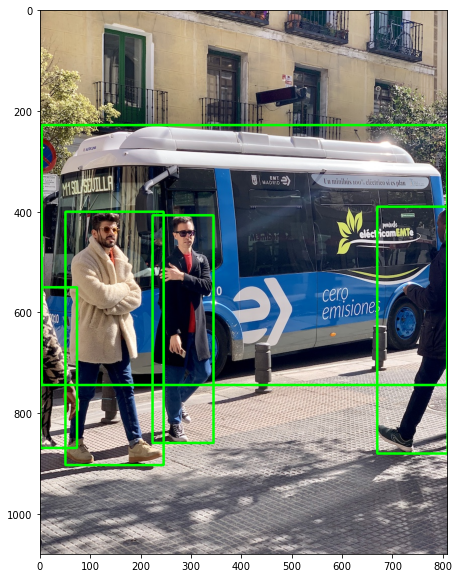

In [34]:
tmp = image.copy()
for i in indexes:
    box = boxes[i]
    left = box[0]
    top = box[1]
    width = box[2]
    height = box[3]
    
    cv2.rectangle(tmp, (left, top), (left + width, top + height), (0,255,0), 3)

plt.figure(figsize=(10, 10))    
plt.imshow(cv2.cvtColor(tmp, cv2.COLOR_BGR2RGB))